# 2. TOP 20 MOMENTUM - IN-SAMPLE PARAMETER STABILITY & PLATEAU CHECK
### STRICT METHODOLOGICAL CONSTRAINT
> **IN-SAMPLE ONLY**: every run here stops at `split.oos_start`. OOS belongs to notebook 03.
### OBJECTIVES
1. **Plateau vs cliff**: the TIS point (63 d, Top 20) must sit on a broad region of the (lookback x Top N) grid, not on a lucky peak. We do **not** move the parameters to the best cell.
2. Cost stress, rebalance-day robustness, regime check (crisis years removed), dose-response by rank bucket, per-year signal ablation.
3. Evidence bar for multiple testing: every cell we look at is a trial.

In [1]:
from t20_tools import *
from scipy import stats
VARIANT = "t20_sp500_v1"
S = setup(VARIANT)
eng, P, rules, panel, TH, reg, G = S.eng, S.P, S.rules, S.panel, S.TH, S.reg, S.cfg["grid"]
check, OOS, N, LB = reg.check, S.OOS, S.P["top_n"], S.P["lookback_days"]
IS = dict(sim_end=OOS)
base = eng.run_backtest(panel, **rules, **IS); bm = eng.perf(base["ret"])
print(f"In-sample {base['ret'].index[0]:%Y-%m-%d} -> {base['ret'].index[-1]:%Y-%m-%d} | configured: CAGR {100 * bm['cagr']:.1f}% Sharpe {bm['sharpe']:.2f} MaxDD {100 * bm['max_dd']:.1f}%")

Data OK: 500 tickers + SPY, last bar 2026-11-09, membership yes
Variant T20M.sp500.stocks.v1 | Top 20 | momentum 63 d | first_wednesday | next_open | slip 5.0 bps/side
Panel: 500 tickers, 2003-01-02 -> 2026-11-09, OOS from 2019-01-01
In-sample 2003-10-20 -> 2018-12-31 | configured: CAGR 9.7% Sharpe 0.69 MaxDD -19.5%


## 3. 2D GRID: LOOKBACK x TOP N (IN-SAMPLE)

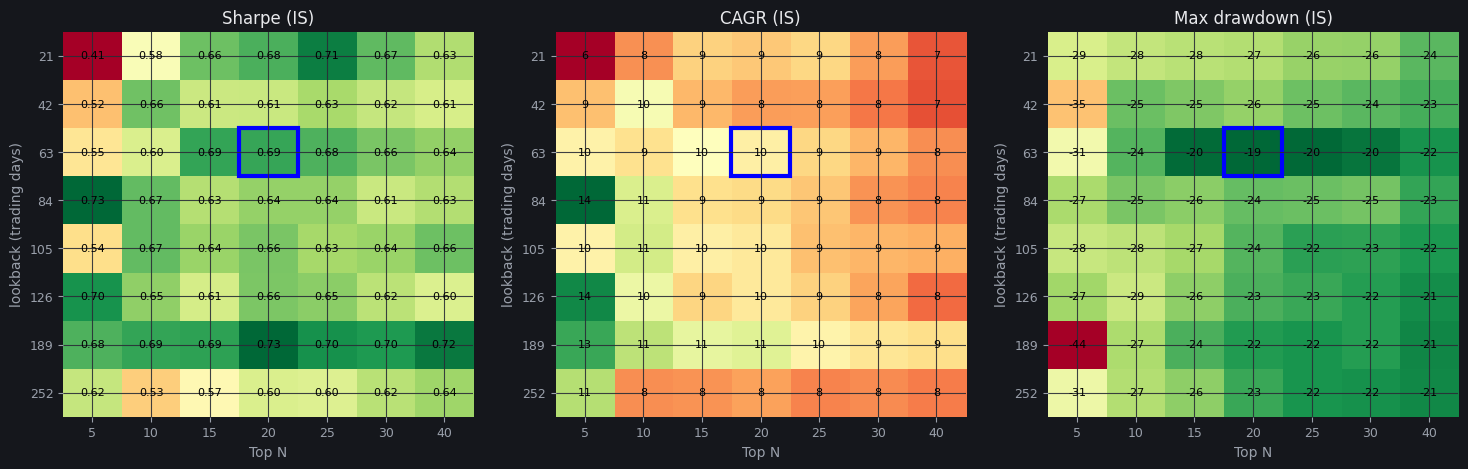

Configured Sharpe 0.69 | rank 11 of 56 | neighbours (3x3) min 0.61 mean 0.65 | grid median 0.64


In [2]:
gr = eng.grid(panel, G["lookback_days_values"], G["top_n_values"], rules, **IS)
piv = {k: gr.pivot(index="lookback", columns="top_n", values=k) for k in ("sharpe", "cagr", "max_dd")}
f, ax = fig(1, 3, figsize=(18, 5))
for a, (k, t) in zip(ax, (("sharpe", "Sharpe"), ("cagr", "CAGR"), ("max_dd", "Max drawdown"))):
    m = piv[k]; im = a.imshow(m.values, cmap="RdYlGn", aspect="auto"); a.set_xticks(range(m.shape[1]), m.columns); a.set_yticks(range(m.shape[0]), m.index)
    a.set_title(f"{t} (IS)"); a.set_xlabel("Top N"); a.set_ylabel("lookback (trading days)")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]): a.text(j, i, f"{m.values[i, j]:.2f}" if k == "sharpe" else f"{100 * m.values[i, j]:.0f}", ha="center", va="center", fontsize=8, color="black")
    a.add_patch(plt.Rectangle((list(m.columns).index(N) - .5, list(m.index).index(LB) - .5), 1, 1, fill=False, ec="blue", lw=3))
plt.show()
sh = piv["sharpe"]; i0, j0 = list(sh.index).index(LB), list(sh.columns).index(N)
nb = sh.iloc[max(i0 - 1, 0):i0 + 2, max(j0 - 1, 0):j0 + 2].to_numpy().ravel(); cfg_sh = sh.iloc[i0, j0]
rank = int((gr["sharpe"] > cfg_sh).sum()) + 1
print(f"Configured Sharpe {cfg_sh:.2f} | rank {rank} of {len(gr)} | neighbours (3x3) min {nb.min():.2f} mean {nb.mean():.2f} | grid median {gr['sharpe'].median():.2f}")

## 4. PLATEAU & ANTI-CLIFF CHECK

In [3]:
share_ok = float((gr["sharpe"] >= TH["SHARPE_MIN"]).mean())
check("4. Plateau", f"Share of grid cells with Sharpe >= {TH['SHARPE_MIN']:g} is >= {TH['PLATEAU_MIN']:.0%}", share_ok >= TH["PLATEAU_MIN"], f"{share_ok:.0%} of {len(gr)} cells")
check("4. Plateau", "3x3 neighbourhood: every neighbour keeps >= 70% of the configured Sharpe", nb.min() >= 0.7 * cfg_sh, f"min neighbour {nb.min():.2f} vs {cfg_sh:.2f}")
check("4. Plateau", "Configured cell is not an isolated peak (Sharpe <= 1.3 x neighbourhood mean)", cfg_sh <= 1.3 * nb.mean(), f"{cfg_sh:.2f} vs mean {nb.mean():.2f}")
check("4. Plateau", "Max drawdown of every neighbour within 10 pts of the configured one", (piv["max_dd"].iloc[max(i0 - 1, 0):i0 + 2, max(j0 - 1, 0):j0 + 2] >= piv["max_dd"].iloc[i0, j0] - .10).all().all(), f"configured {100 * piv['max_dd'].iloc[i0, j0]:.1f}%")
# declared regime check: remove the momentum-crash years (2009 rebound, 2020) and the 2008 crash
ex = base["ret"][~base["ret"].index.year.isin([2008, 2009, 2020])]; me = eng.perf(ex)
check("4. Plateau", "Sharpe stays >= 0.4 without 2008, 2009 and 2020", me["sharpe"] >= .4, f"{me['sharpe']:.2f}")

   [PASS] Share of grid cells with Sharpe >= 0.5 is >= 60%  ->  98% of 56 cells
   [PASS] 3x3 neighbourhood: every neighbour keeps >= 70% of the configured Sharpe  ->  min neighbour 0.61 vs 0.69
   [PASS] Configured cell is not an isolated peak (Sharpe <= 1.3 x neighbourhood mean)  ->  0.69 vs mean 0.65
   [PASS] Max drawdown of every neighbour within 10 pts of the configured one  ->  configured -19.5%
   [PASS] Sharpe stays >= 0.4 without 2008, 2009 and 2020  ->  0.69


'PASS'

## 3.5 COST STRESS (SLIPPAGE PER SIDE)

In [4]:
cs = pd.DataFrame({b: eng.perf(eng.run_backtest(panel, **{**rules, "slip_bps_per_side": b}, **IS)["ret"]) for b in (0, 5, 10, 20, 40)}).T[["cagr", "sharpe", "max_dd"]]
print(cs.round(3).to_string())
check("3.5 Costs", "Sharpe >= 0.4 with 4x the slippage (20 bps per side)", cs.loc[20, "sharpe"] >= .4, f"{cs.loc[20, 'sharpe']:.2f}")
check("3.5 Costs", "Still positive CAGR at 40 bps per side", cs.loc[40, "cagr"] > 0, f"{100 * cs.loc[40, 'cagr']:.1f}%")

     cagr  sharpe  max_dd
0   0.103   0.726  -0.192
5   0.097   0.687  -0.195
10  0.090   0.648  -0.197
20  0.078   0.570  -0.203
40  0.053   0.413  -0.220
   [PASS] Sharpe >= 0.4 with 4x the slippage (20 bps per side)  ->  0.57
   [PASS] Still positive CAGR at 40 bps per side  ->  5.3%


'PASS'

## 5. DOSE-RESPONSE: DOES A HIGHER RANK MEAN A BETTER NEXT MONTH?
Eligible names sorted by momentum and cut into rank buckets; mean forward 21-day return of each bucket (in-sample rebalances).

0-10      1.31
10-20     1.09
20-40     0.85
40-80     1.02
80-400    0.94
   [PASS] Top bucket beats the bottom bucket  ->  +1.31% vs +0.94% / month
   [PASS] Bucket returns decrease with rank (Spearman < -0.5)  ->  rho -0.70


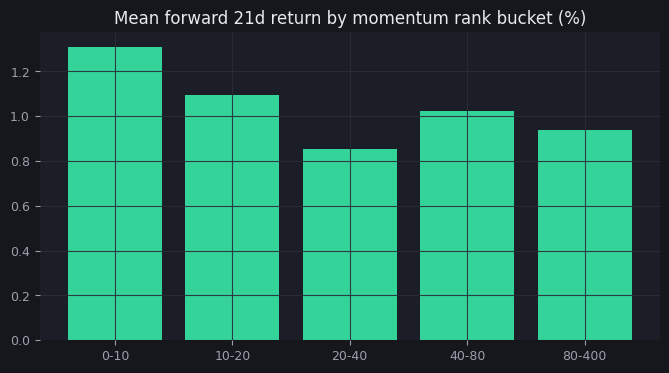

In [5]:
reb, _ = eng.calendar_flags(panel.dates, rules["rebalance"]); mom, sS, sF = panel.mom(LB), panel.sma(rules["stock_ma"]), panel.sma(rules["fast_ma"])
cuts, rows = [(0, 10), (10, 20), (20, 40), (40, 80), (80, 400)], []
for t in np.flatnonzero(reb):
    if t < 260 or t + 21 >= len(panel.dates) or panel.dates[t] >= OOS: continue
    el = panel.member[t] & ~np.isnan(mom[t]) & (panel.adv[t] >= rules["min_adv_shares"]) & (panel.close[t] > sS[t]) & (panel.close[t] > sF[t]); ix = np.flatnonzero(el)
    if len(ix) < 40: continue
    ix = ix[np.argsort(-mom[t, ix])]; fwd = panel.close_ff[t + 21, ix] / panel.close_ff[t, ix] - 1
    rows.append({f"{a}-{b}": fwd[a:b].mean() for a, b in cuts if len(fwd) > a})
bk = pd.DataFrame(rows); mb = 100 * bk.mean(); print(mb.round(2).to_string())
rho = stats.spearmanr(range(len(mb)), mb.values)[0]
check("5. Dose-response", "Top bucket beats the bottom bucket", mb.iloc[0] > mb.iloc[-1], f"{mb.iloc[0]:+.2f}% vs {mb.iloc[-1]:+.2f}% / month")
check("5. Dose-response", "Bucket returns decrease with rank (Spearman < -0.5)", rho < -.5, f"rho {rho:+.2f}")
f, a = fig(figsize=(8, 4)); a.bar(mb.index, mb.values, color=GREEN); a.set_title("Mean forward 21d return by momentum rank bucket (%)"); plt.show()

## 6. REBALANCE-DAY ROBUSTNESS
TIS says "first Wednesday, be consistent". The edge must not depend on that exact day.

In [6]:
tm = {r: eng.perf(eng.run_backtest(panel, **{**rules, "rebalance": r}, **IS)["ret"]) for r in ("first_trading_day", "first_monday", "first_wednesday", "second_wednesday", "third_wednesday", "first_friday")}
tm = pd.DataFrame(tm).T[["cagr", "sharpe", "max_dd"]]; print(tm.round(3).to_string())
check("6. Timing", "Every rebalance day keeps >= 70% of the configured Sharpe", (tm["sharpe"] >= .7 * tm.loc["first_wednesday", "sharpe"]).all(), f"min {tm['sharpe'].min():.2f} vs {tm.loc['first_wednesday', 'sharpe']:.2f}")
check("6. Timing", "Sharpe range across days <= 0.35", tm["sharpe"].max() - tm["sharpe"].min() <= .35, f"range {tm['sharpe'].max() - tm['sharpe'].min():.2f}")

                    cagr  sharpe  max_dd
first_trading_day  0.093   0.663  -0.213
first_monday       0.090   0.640  -0.196
first_wednesday    0.097   0.687  -0.195
second_wednesday   0.096   0.683  -0.208
third_wednesday    0.106   0.747  -0.234
first_friday       0.095   0.689  -0.226
   [PASS] Every rebalance day keeps >= 70% of the configured Sharpe  ->  min 0.64 vs 0.69
   [PASS] Sharpe range across days <= 0.35  ->  range 0.11


'PASS'

## 7. SIGNAL ABLATION BY YEAR (IN-SAMPLE)
Strategy return per calendar year minus the equal-weight eligible universe (rebalanced monthly, no filters): where does the edge come from?

In [7]:
pure = eng.run_backtest(panel, **{**rules, "market_filter": False, "stock_stop": False, "stock_trend": False}, **IS)["ret"]
yr = pd.DataFrame({"strategy": base["ret"].groupby(base["ret"].index.year).apply(lambda r: (1 + r).prod() - 1),
                   "pure_top_n": pure.groupby(pure.index.year).apply(lambda r: (1 + r).prod() - 1),
                   "spy": eng.benchmark_ret(panel, base["ret"]).groupby(base["ret"].index.year).apply(lambda r: (1 + r).prod() - 1)})
yr["vs_spy"] = yr["strategy"] - yr["spy"]; print(yr.round(3).to_string())
check("7. Ablation", "Beats SPY in >= 50% of the in-sample years", (yr["vs_spy"] > 0).mean() >= .5, f"{(yr['vs_spy'] > 0).mean():.0%}")
check("7. Ablation", "Wins in bear years (SPY < 0): beats SPY in every one", (yr.loc[yr["spy"] < 0, "vs_spy"] > 0).all(), f"bear years {yr.index[yr['spy'] < 0].tolist()}")

      strategy  pure_top_n    spy  vs_spy
Date                                     
2003    -0.032      -0.026  0.072  -0.104
2004     0.189       0.332  0.107   0.082
2005     0.065       0.155  0.048   0.017
2006     0.046       0.145  0.158  -0.113
2007     0.146       0.219  0.051   0.094
2008     0.000      -0.524 -0.368   0.368
2009     0.192       0.366  0.264  -0.072
2010     0.018       0.200  0.151  -0.133
2011    -0.025      -0.044  0.019  -0.044
2012     0.182       0.294  0.160   0.022
2013     0.448       0.546  0.323   0.125
2014     0.040       0.152  0.135  -0.095
2015    -0.106       0.107  0.012  -0.118
2016     0.361       0.362  0.120   0.241
2017     0.151       0.145  0.217  -0.066
2018    -0.061      -0.044 -0.046  -0.015
   [FAIL] Beats SPY in >= 50% of the in-sample years  ->  44%
   [FAIL] Wins in bear years (SPY < 0): beats SPY in every one  ->  bear years [2008, 2018]


'FAIL'

## 8. EVIDENCE BAR (MULTIPLE TESTING)
Trials looked at in this notebook: grid cells + rebalance days. Bonferroni-corrected one-sided t needed for the monthly returns of the configured rule.

In [8]:
n_trials = len(gr) + len(tm); t_need = stats.norm.ppf(1 - TH["ALPHA"] / n_trials)
t_is = eng.tstat(eng.monthly(base["ret"]))
print(f"trials {n_trials} | t needed {t_need:.2f} | configured monthly t {t_is:.2f}")
check("8. Evidence", f"Monthly t >= Bonferroni bar for {n_trials} trials", t_is >= t_need, f"t {t_is:.2f} vs {t_need:.2f}")
check("8. Evidence", f"Monthly t >= {TH['T_MIN']:g}", t_is >= TH["T_MIN"], f"t {t_is:.2f}")

trials 62 | t needed 3.15 | configured monthly t 2.95
   [FAIL] Monthly t >= Bonferroni bar for 62 trials  ->  t 2.95 vs 3.15
   [PASS] Monthly t >= 2  ->  t 2.95


'PASS'

## 9. CHECKS REGISTRY, VERDICT & NEXT STEPS

In [9]:
ESSENTIAL = [("4. Plateau", "Share of grid", "Most of the grid fails: the TIS rule is not robust to its own parameters."),
    ("4. Plateau", "3x3 neighbourhood", "A neighbour collapses: cliff, not plateau."), ("4. Plateau", "Configured cell is not", "Isolated peak: suspect of luck."),
    ("3.5 Costs", "Sharpe >= 0.4 with 4x", "Edge dies with realistic slippage."), ("5. Dose-response", "Top bucket", "Higher rank does not mean higher return: no momentum effect."),
    ("6. Timing", "Every rebalance day", "Result depends on the exact rebalance day: fragile."), ("7. Ablation", "Wins in bear years", "Protection leg does not work in the in-sample bears.")]
go = gate(reg, ESSENTIAL, headline=f"| configured Sharpe {cfg_sh:.2f}, rank {rank}/{len(gr)}")
print("\nNEXT STEP:", "03_Top20_Momentum_Robustness_Testing.ipynb (rules stay FROZEN at 63 d / Top 20)." if go else "do not move to the best cell: record as rejected or keep as conditional candidate.")

DECISION: STOP  (6 PASS / 1 FAIL / 0 SKIP of 7 essential)  | configured Sharpe 0.69, rank 11/56

4. Plateau
   [PASS] Share of grid cells with Sharpe >= 0.5 is >= 60%  ->  98% of 56 cells
   [PASS] 3x3 neighbourhood: every neighbour keeps >= 70% of the configured Sharpe  ->  min neighbour 0.61 vs 0.69
   [PASS] Configured cell is not an isolated peak (Sharpe <= 1.3 x neighbourhood mean)  ->  0.69 vs mean 0.65

3.5 Costs
   [PASS] Sharpe >= 0.4 with 4x the slippage (20 bps per side)  ->  0.57

5. Dose-response
   [PASS] Top bucket beats the bottom bucket  ->  +1.31% vs +0.94% / month

6. Timing
   [PASS] Every rebalance day keeps >= 70% of the configured Sharpe  ->  min 0.64 vs 0.69

7. Ablation
   [FAIL] Wins in bear years (SPY < 0): beats SPY in every one  ->  bear years [2008, 2018]

OTHER CHECKS (informative, they do not decide GO / STOP)
   [PASS] 4. Plateau · Max drawdown of every neighbour within 10 pts of the configured one  ->  configured -19.5%
   [PASS] 4. Plateau · Sharpe st

## 10. SAVE

In [10]:
S.vc.save_json(S.cfg, "02_optimization.json", dict(variant=S.cfg["id"], go=bool(go), configured_sharpe=cfg_sh, rank=rank, n_trials=n_trials, grid=gr.round(4).to_dict("records"),
    costs=cs.round(4).to_dict("index"), timing=tm.round(4).to_dict("index"), checks=reg.df().to_dict("records")))

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Top20_Momentum/runs/t20_sp500_v1/02_optimization.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Top20_Momentum/runs/t20_sp500_v1/02_optimization.json')